In [10]:
import pandas as pd
import numpy as np

# Let's generate a dummy matches.csv dataset
n_matches = 100
teams = ['Mumbai Indians', 'Kolkata Knight Riders', 'Royal Challengers Bangalore', 'Deccan Chargers', 'Chennai Super Kings', 'Delhi Daredevils', 'Rajasthan Royals', 'Kings XI Punjab']
cities = ['Mumbai', 'Kolkata', 'Bangalore', 'Hyderabad', 'Chennai', 'Delhi', 'Jaipur', 'Chandigarh']
venues = ['Wankhede Stadium', 'Eden Gardens', 'M. Chinnaswamy Stadium', 'Rajiv Gandhi International Stadium', 'MA Chidambaram Stadium', 'Feroz Shah Kotla', 'Sawai Mansingh Stadium', 'Punjab Cricket Association Stadium']

np.random.seed(42)

matches_df = pd.DataFrame({
    'id': range(1, n_matches + 1),
    'season': np.random.choice([2015, 2016, 2017, 2018, 2019], n_matches),
    'city': np.random.choice(cities, n_matches),
    'date': pd.date_range(start='2015-04-01', periods=n_matches, freq='D').strftime('%Y-%m-%d'),
    'team1': np.random.choice(teams, n_matches),
    'team2': np.random.choice(teams, n_matches),
    'toss_winner': np.random.choice(teams, n_matches),
    'toss_decision': np.random.choice(['bat', 'field'], n_matches),
    'result': np.random.choice(['normal', 'tie', 'no result'], n_matches, p=[0.95, 0.03, 0.02]),
    'dl_applied': np.random.choice([0, 1], n_matches, p=[0.95, 0.05]),
    'winner': np.random.choice(teams + ['No Result'], n_matches),
    'win_by_runs': np.random.randint(0, 100, n_matches),
    'win_by_wickets': np.random.randint(0, 10, n_matches),
    'player_of_match': np.random.choice(['MS Dhoni', 'Virat Kohli', 'RG Sharma', 'AB de Villiers', 'DA Warner'], n_matches),
    'venue': np.random.choice(venues, n_matches),
    'umpire1': np.random.choice(['HDPK Dharmasena', 'Asad Rauf', 'AK Chaudhary'], n_matches),
    'umpire2': np.random.choice(['SJA Taufel', 'C Shamshuddin', 'S Ravi'], n_matches),
    'umpire3': [np.nan] * n_matches
})

# Ensure win_by_runs is 0 if won by wickets and vice versa to be realistic
matches_df.loc[matches_df['win_by_wickets'] > 0, 'win_by_runs'] = 0
matches_df.to_csv('matches.csv', index=False)

# Let's generate a dummy deliveries.csv dataset
deliveries_data = []
for match_id in range(1, n_matches + 1):
    for inning in [1, 2]:
        batting = np.random.choice(teams)
        bowling = np.random.choice([t for t in teams if t != batting])
        for over in range(1, 21):
            for ball in range(1, 7):
                deliveries_data.append({
                    'match_id': match_id,
                    'inning': inning,
                    'batting_team': batting,
                    'bowling_team': bowling,
                    'over': over,
                    'ball': ball,
                    'batsman': np.random.choice(['V Kohli', 'MS Dhoni', 'RG Sharma']),
                    'non_striker': np.random.choice(['S Dhawan', 'KL Rahul']),
                    'bowler': np.random.choice(['JJ Bumrah', 'B Kumar', 'YS Chahal']),
                    'is_super_over': 0,
                    'wide_runs': np.random.choice([0, 1], p=[0.95, 0.05]),
                    'bye_runs': 0,
                    'legbye_runs': 0,
                    'noball_runs': 0,
                    'penalty_runs': 0,
                    'batsman_runs': np.random.choice([0, 1, 2, 4, 6], p=[0.4, 0.4, 0.1, 0.07, 0.03]),
                    'extra_runs': 0,
                    'total_runs': 0,
                    'player_dismissed': np.random.choice([np.nan, 'V Kohli'], p=[0.98, 0.02]),
                    'dismissal_kind': np.random.choice([np.nan, 'caught', 'bowled'], p=[0.98, 0.01, 0.01]),
                    'fielder': np.random.choice([np.nan, 'MS Dhoni'], p=[0.99, 0.01])
                })

deliveries_df = pd.DataFrame(deliveries_data)
deliveries_df['extra_runs'] = deliveries_df['wide_runs']
deliveries_df['total_runs'] = deliveries_df['batsman_runs'] + deliveries_df['extra_runs']
deliveries_df.to_csv('deliveries.csv', index=False)

print("Created dummy matches.csv and deliveries.csv files successfully!")

Created dummy matches.csv and deliveries.csv files successfully!


# 🏏 IPL Data Analysis Case Study

# Problem Statement

The Indian Premier League (IPL) is one of the most popular T20 cricket leagues in the world, generating a vast amount of match and player data every season. This data provides an excellent opportunity to analyze patterns, team strategies, and player performances.

The objective of this case study is to perform **Exploratory Data Analysis (EDA)** on IPL datasets to uncover meaningful insights related to:

- Team performance across seasons  
- Impact of toss on match outcomes  
- Player performance (batsmen and bowlers)  
- Match-winning factors (runs vs wickets)  
- Scoring trends across different overs  

---

## 🎯 Goals of the Analysis

- Understand overall IPL match trends  
- Identify the most successful teams  
- Analyze top-performing players  
- Study the effect of toss decisions  
- Explore scoring patterns during matches  

---

## ❓ Key Questions to Answer

- Which teams have been the most successful in IPL history?  
- Does winning the toss give a significant advantage?  
- Who are the top batsmen and bowlers?  
- Are matches more often won by chasing or defending?  
- Which overs are the most crucial for scoring runs?  

---

## 📊 Expected Outcome

The analysis will provide meaningful insights into team strategies, player impact, and match dynamics. These insights can be useful for:

- Teams for strategic planning  
- Analysts for performance evaluation  
- Fans for deeper understanding of the game  

# Dataset Description

The dataset used in this analysis consists of two files:

- `matches.csv` → Contains match-level information  
- `deliveries.csv` → Contains ball-by-ball data  

We will load both datasets and explore their structure, columns, and relationships.

In [11]:
import pandas as pd
import warnings
warnings.filterwarnings("ignore")

# Load the generated datasets
matches = pd.read_csv('matches.csv')
deliveries = pd.read_csv('deliveries.csv')

In [12]:
matches

,id,season,city,date,team1,team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,umpire1,umpire2,umpire3
0,1,2018,Hyderabad,2015-04-01,Royal Challengers Bangalore,Royal Challengers Bangalore,Royal Challengers Bangalore,field,normal,1,Mumbai Indians,0,7,MS Dhoni,Sawai Mansingh Stadium,Asad Rauf,C Shamshuddin,NaN
1,2,2019,Jaipur,2015-04-02,Mumbai Indians,Deccan Chargers,Kolkata Knight Riders,field,normal,0,Chennai Super Kings,0,9,DA Warner,M. Chinnaswamy Stadium,AK Chaudhary,SJA Taufel,NaN
2,3,2017,Mumbai,2015-04-03,Delhi Daredevils,Mumbai Indians,Chennai Super Kings,bat,normal,0,Chennai Super Kings,0,2,DA Warner,Feroz Shah Kotla,Asad Rauf,SJA Taufel,NaN
3,4,2019,Chandigarh,2015-04-04,Chennai Super Kings,Mumbai Indians,Delhi Daredevils,bat,normal,0,Delhi Daredevils,0,4,RG Sharma,Eden Gardens,Asad Rauf,C Shamshuddin,NaN
4,5,2019,Hyderabad,2015-04-05,Mumbai Indians,Kolkata Knight Riders,Mumbai Indians,bat,normal,0,Royal Challengers Bangalore,0,5,MS Dhoni,Rajiv Gandhi International Stadium,AK Chaudhary,SJA Taufel,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,96,2017,Mumbai,2015-07-05,Kings XI Punjab,Chennai Super Kings,Mumbai Indians,field,no result,0,No Result,0,3,AB de Villiers,M. Chinnaswamy Stadium,Asad Rauf,S Ravi,NaN
96,97,2019,Bangalore,2015-07-06,Rajasthan Royals,Royal Challengers Bangalore,Kings XI Punjab,bat,normal,0,No Result,0,6,DA Warner,Wankhede Stadium,HDPK Dharmasena,C Shamshuddin,NaN
97,98,2016,Jaipur,2015-07-07,Kolkata Knight Riders,Delhi Daredevils,Kings XI Punjab,bat,normal,0,Delhi Daredevils,0,3,MS Dhoni,Rajiv Gandhi International Stadium,HDPK Dharmasena,S Ravi,NaN
98,99,2016,Delhi,2015-07-08,Kings XI Punjab,Kings XI Punjab,Delhi Daredevils,bat,normal,0,Kings XI Punjab,0,5,MS Dhoni,Sawai Mansingh Stadium,HDPK Dharmasena,SJA Taufel,NaN


In [13]:
deliveries

,match_id,inning,batting_team,bowling_team,over,ball,batsman,non_striker,bowler,is_super_over,...,bye_runs,legbye_runs,noball_runs,penalty_runs,batsman_runs,extra_runs,total_runs,player_dismissed,dismissal_kind,fielder
0,1,1,Kolkata Knight Riders,Delhi Daredevils,1,1,MS Dhoni,KL Rahul,YS Chahal,0,...,0,0,0,0,1,0,1,NaN,NaN,NaN
1,1,1,Kolkata Knight Riders,Delhi Daredevils,1,2,RG Sharma,S Dhawan,B Kumar,0,...,0,0,0,0,0,0,0,NaN,NaN,NaN
2,1,1,Kolkata Knight Riders,Delhi Daredevils,1,3,MS Dhoni,S Dhawan,YS Chahal,0,...,0,0,0,0,1,0,1,NaN,NaN,NaN
3,1,1,Kolkata Knight Riders,Delhi Daredevils,1,4,RG Sharma,KL Rahul,YS Chahal,0,...,0,0,0,0,1,0,1,NaN,NaN,NaN
4,1,1,Kolkata Knight Riders,Delhi Daredevils,1,5,V Kohli,KL Rahul,B Kumar,0,...,0,0,0,0,1,0,1,V Kohli,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23995,100,2,Chennai Super Kings,Deccan Chargers,20,2,RG Sharma,KL Rahul,B Kumar,0,...,0,0,0,0,1,0,1,NaN,NaN,NaN
23996,100,2,Chennai Super Kings,Deccan Chargers,20,3,RG Sharma,KL Rahul,JJ Bumrah,0,...,0,0,0,0,1,0,1,NaN,NaN,NaN
23997,100,2,Chennai Super Kings,Deccan Chargers,20,4,V Kohli,KL Rahul,JJ Bumrah,0,...,0,0,0,0,0,0,0,NaN,NaN,NaN
23998,100,2,Chennai Super Kings,Deccan Chargers,20,5,RG Sharma,S Dhawan,B Kumar,0,...,0,0,0,0,1,0,1,NaN,NaN,NaN


In [14]:
print("Matches Columns:")
print(matches.columns)

print("\nDeliveries Columns:")
print(deliveries.columns)

Matches Columns:
Index(['id', 'season', 'city', 'date', 'team1', 'team2', 'toss_winner',
       'toss_decision', 'result', 'dl_applied', 'winner', 'win_by_runs',
       'win_by_wickets', 'player_of_match', 'venue', 'umpire1', 'umpire2',
       'umpire3'],
      dtype='object')

Deliveries Columns:
Index(['match_id', 'inning', 'batting_team', 'bowling_team', 'over', 'ball',
       'batsman', 'non_striker', 'bowler', 'is_super_over', 'wide_runs',
       'bye_runs', 'legbye_runs', 'noball_runs', 'penalty_runs',
       'batsman_runs', 'extra_runs', 'total_runs', 'player_dismissed',
       'dismissal_kind', 'fielder'],
      dtype='object')


### 📁 Matches Dataset (matches.csv) – Column Description

| Column Name        | Description |
|-------------------|------------|
| id                | Unique identifier for each match |
| season            | IPL season/year in which the match was played |
| city              | City where the match took place |
| date              | Date of the match |
| team1             | First team playing the match |
| team2             | Second team playing the match |
| toss_winner       | Team that won the toss |
| toss_decision     | Decision taken after winning the toss (bat/field) |
| result            | Type of result (normal, tie, no result) |
| dl_applied        | Indicates if Duckworth-Lewis method was applied (1 = Yes, 0 = No) |
| winner            | Team that won the match |
| win_by_runs       | Number of runs by which the match was won |
| win_by_wickets    | Number of wickets by which the match was won |
| player_of_match   | Player awarded as the best performer of the match |
| venue             | Stadium where the match was played |
| umpire1           | First on-field umpire |
| umpire2           | Second on-field umpire |
| umpire3           | Third umpire (if applicable) |

### 📁 Deliveries Dataset (deliveries.csv) – Column Description

| Column Name        | Description |
|-------------------|------------|
| match_id          | Unique match identifier (links to matches.id) |
| inning            | Inning number (1 or 2) |
| batting_team      | Team that is batting |
| bowling_team      | Team that is bowling |
| over              | Over number in the match |
| ball              | Ball number within the over |
| batsman           | Name of the batsman facing the ball |
| non_striker       | Batsman at the non-striker end |
| bowler            | Name of the bowler |
| is_super_over     | Indicates if the delivery is part of a super over (1 = Yes, 0 = No) |
| wide_runs         | Runs scored as wides |
| bye_runs          | Runs scored as byes |
| legbye_runs       | Runs scored as leg byes |
| noball_runs       | Runs scored as no-balls |
| penalty_runs      | Extra penalty runs awarded |
| batsman_runs      | Runs scored by the batsman |
| extra_runs        | Total extra runs (wide, no-ball, etc.) |
| total_runs        | Total runs scored on that delivery |
| player_dismissed  | Name of the player dismissed (if any) |
| dismissal_kind    | Type of dismissal (bowled, caught, run out, etc.) |
| fielder           | Name of the fielder involved in dismissal |

In [15]:
# Dataset info
print("Matches Info:")
matches.info()

print("\nDeliveries Info:")
deliveries.info()

Matches Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               100 non-null    int64  
 1   season           100 non-null    int64  
 2   city             100 non-null    object 
 3   date             100 non-null    object 
 4   team1            100 non-null    object 
 5   team2            100 non-null    object 
 6   toss_winner      100 non-null    object 
 7   toss_decision    100 non-null    object 
 8   result           100 non-null    object 
 9   dl_applied       100 non-null    int64  
 10  winner           100 non-null    object 
 11  win_by_runs      100 non-null    int64  
 12  win_by_wickets   100 non-null    int64  
 13  player_of_match  100 non-null    object 
 14  venue            100 non-null    object 
 15  umpire1          100 non-null    object 
 16  umpire2          100 non-null    object 
 17  ump

# Preprocessing

In [16]:
matches

,id,season,city,date,team1,team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,umpire1,umpire2,umpire3
0,1,2018,Hyderabad,2015-04-01,Royal Challengers Bangalore,Royal Challengers Bangalore,Royal Challengers Bangalore,field,normal,1,Mumbai Indians,0,7,MS Dhoni,Sawai Mansingh Stadium,Asad Rauf,C Shamshuddin,NaN
1,2,2019,Jaipur,2015-04-02,Mumbai Indians,Deccan Chargers,Kolkata Knight Riders,field,normal,0,Chennai Super Kings,0,9,DA Warner,M. Chinnaswamy Stadium,AK Chaudhary,SJA Taufel,NaN
2,3,2017,Mumbai,2015-04-03,Delhi Daredevils,Mumbai Indians,Chennai Super Kings,bat,normal,0,Chennai Super Kings,0,2,DA Warner,Feroz Shah Kotla,Asad Rauf,SJA Taufel,NaN
3,4,2019,Chandigarh,2015-04-04,Chennai Super Kings,Mumbai Indians,Delhi Daredevils,bat,normal,0,Delhi Daredevils,0,4,RG Sharma,Eden Gardens,Asad Rauf,C Shamshuddin,NaN
4,5,2019,Hyderabad,2015-04-05,Mumbai Indians,Kolkata Knight Riders,Mumbai Indians,bat,normal,0,Royal Challengers Bangalore,0,5,MS Dhoni,Rajiv Gandhi International Stadium,AK Chaudhary,SJA Taufel,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,96,2017,Mumbai,2015-07-05,Kings XI Punjab,Chennai Super Kings,Mumbai Indians,field,no result,0,No Result,0,3,AB de Villiers,M. Chinnaswamy Stadium,Asad Rauf,S Ravi,NaN
96,97,2019,Bangalore,2015-07-06,Rajasthan Royals,Royal Challengers Bangalore,Kings XI Punjab,bat,normal,0,No Result,0,6,DA Warner,Wankhede Stadium,HDPK Dharmasena,C Shamshuddin,NaN
97,98,2016,Jaipur,2015-07-07,Kolkata Knight Riders,Delhi Daredevils,Kings XI Punjab,bat,normal,0,Delhi Daredevils,0,3,MS Dhoni,Rajiv Gandhi International Stadium,HDPK Dharmasena,S Ravi,NaN
98,99,2016,Delhi,2015-07-08,Kings XI Punjab,Kings XI Punjab,Delhi Daredevils,bat,normal,0,Kings XI Punjab,0,5,MS Dhoni,Sawai Mansingh Stadium,HDPK Dharmasena,SJA Taufel,NaN


In [17]:
matches.drop(columns=['umpire3'])

,id,season,city,date,team1,team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,umpire1,umpire2
0,1,2018,Hyderabad,2015-04-01,Royal Challengers Bangalore,Royal Challengers Bangalore,Royal Challengers Bangalore,field,normal,1,Mumbai Indians,0,7,MS Dhoni,Sawai Mansingh Stadium,Asad Rauf,C Shamshuddin
1,2,2019,Jaipur,2015-04-02,Mumbai Indians,Deccan Chargers,Kolkata Knight Riders,field,normal,0,Chennai Super Kings,0,9,DA Warner,M. Chinnaswamy Stadium,AK Chaudhary,SJA Taufel
2,3,2017,Mumbai,2015-04-03,Delhi Daredevils,Mumbai Indians,Chennai Super Kings,bat,normal,0,Chennai Super Kings,0,2,DA Warner,Feroz Shah Kotla,Asad Rauf,SJA Taufel
3,4,2019,Chandigarh,2015-04-04,Chennai Super Kings,Mumbai Indians,Delhi Daredevils,bat,normal,0,Delhi Daredevils,0,4,RG Sharma,Eden Gardens,Asad Rauf,C Shamshuddin
4,5,2019,Hyderabad,2015-04-05,Mumbai Indians,Kolkata Knight Riders,Mumbai Indians,bat,normal,0,Royal Challengers Bangalore,0,5,MS Dhoni,Rajiv Gandhi International Stadium,AK Chaudhary,SJA Taufel
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,96,2017,Mumbai,2015-07-05,Kings XI Punjab,Chennai Super Kings,Mumbai Indians,field,no result,0,No Result,0,3,AB de Villiers,M. Chinnaswamy Stadium,Asad Rauf,S Ravi
96,97,2019,Bangalore,2015-07-06,Rajasthan Royals,Royal Challengers Bangalore,Kings XI Punjab,bat,normal,0,No Result,0,6,DA Warner,Wankhede Stadium,HDPK Dharmasena,C Shamshuddin
97,98,2016,Jaipur,2015-07-07,Kolkata Knight Riders,Delhi Daredevils,Kings XI Punjab,bat,normal,0,Delhi Daredevils,0,3,MS Dhoni,Rajiv Gandhi International Stadium,HDPK Dharmasena,S Ravi
98,99,2016,Delhi,2015-07-08,Kings XI Punjab,Kings XI Punjab,Delhi Daredevils,bat,normal,0,Kings XI Punjab,0,5,MS Dhoni,Sawai Mansingh Stadium,HDPK Dharmasena,SJA Taufel


In [18]:
matches

,id,season,city,date,team1,team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,umpire1,umpire2,umpire3
0,1,2018,Hyderabad,2015-04-01,Royal Challengers Bangalore,Royal Challengers Bangalore,Royal Challengers Bangalore,field,normal,1,Mumbai Indians,0,7,MS Dhoni,Sawai Mansingh Stadium,Asad Rauf,C Shamshuddin,NaN
1,2,2019,Jaipur,2015-04-02,Mumbai Indians,Deccan Chargers,Kolkata Knight Riders,field,normal,0,Chennai Super Kings,0,9,DA Warner,M. Chinnaswamy Stadium,AK Chaudhary,SJA Taufel,NaN
2,3,2017,Mumbai,2015-04-03,Delhi Daredevils,Mumbai Indians,Chennai Super Kings,bat,normal,0,Chennai Super Kings,0,2,DA Warner,Feroz Shah Kotla,Asad Rauf,SJA Taufel,NaN
3,4,2019,Chandigarh,2015-04-04,Chennai Super Kings,Mumbai Indians,Delhi Daredevils,bat,normal,0,Delhi Daredevils,0,4,RG Sharma,Eden Gardens,Asad Rauf,C Shamshuddin,NaN
4,5,2019,Hyderabad,2015-04-05,Mumbai Indians,Kolkata Knight Riders,Mumbai Indians,bat,normal,0,Royal Challengers Bangalore,0,5,MS Dhoni,Rajiv Gandhi International Stadium,AK Chaudhary,SJA Taufel,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,96,2017,Mumbai,2015-07-05,Kings XI Punjab,Chennai Super Kings,Mumbai Indians,field,no result,0,No Result,0,3,AB de Villiers,M. Chinnaswamy Stadium,Asad Rauf,S Ravi,NaN
96,97,2019,Bangalore,2015-07-06,Rajasthan Royals,Royal Challengers Bangalore,Kings XI Punjab,bat,normal,0,No Result,0,6,DA Warner,Wankhede Stadium,HDPK Dharmasena,C Shamshuddin,NaN
97,98,2016,Jaipur,2015-07-07,Kolkata Knight Riders,Delhi Daredevils,Kings XI Punjab,bat,normal,0,Delhi Daredevils,0,3,MS Dhoni,Rajiv Gandhi International Stadium,HDPK Dharmasena,S Ravi,NaN
98,99,2016,Delhi,2015-07-08,Kings XI Punjab,Kings XI Punjab,Delhi Daredevils,bat,normal,0,Kings XI Punjab,0,5,MS Dhoni,Sawai Mansingh Stadium,HDPK Dharmasena,SJA Taufel,NaN


In [19]:
matches.drop(columns=['umpire3'], inplace=True)

In [20]:
matches

,id,season,city,date,team1,team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,umpire1,umpire2
0,1,2018,Hyderabad,2015-04-01,Royal Challengers Bangalore,Royal Challengers Bangalore,Royal Challengers Bangalore,field,normal,1,Mumbai Indians,0,7,MS Dhoni,Sawai Mansingh Stadium,Asad Rauf,C Shamshuddin
1,2,2019,Jaipur,2015-04-02,Mumbai Indians,Deccan Chargers,Kolkata Knight Riders,field,normal,0,Chennai Super Kings,0,9,DA Warner,M. Chinnaswamy Stadium,AK Chaudhary,SJA Taufel
2,3,2017,Mumbai,2015-04-03,Delhi Daredevils,Mumbai Indians,Chennai Super Kings,bat,normal,0,Chennai Super Kings,0,2,DA Warner,Feroz Shah Kotla,Asad Rauf,SJA Taufel
3,4,2019,Chandigarh,2015-04-04,Chennai Super Kings,Mumbai Indians,Delhi Daredevils,bat,normal,0,Delhi Daredevils,0,4,RG Sharma,Eden Gardens,Asad Rauf,C Shamshuddin
4,5,2019,Hyderabad,2015-04-05,Mumbai Indians,Kolkata Knight Riders,Mumbai Indians,bat,normal,0,Royal Challengers Bangalore,0,5,MS Dhoni,Rajiv Gandhi International Stadium,AK Chaudhary,SJA Taufel
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,96,2017,Mumbai,2015-07-05,Kings XI Punjab,Chennai Super Kings,Mumbai Indians,field,no result,0,No Result,0,3,AB de Villiers,M. Chinnaswamy Stadium,Asad Rauf,S Ravi
96,97,2019,Bangalore,2015-07-06,Rajasthan Royals,Royal Challengers Bangalore,Kings XI Punjab,bat,normal,0,No Result,0,6,DA Warner,Wankhede Stadium,HDPK Dharmasena,C Shamshuddin
97,98,2016,Jaipur,2015-07-07,Kolkata Knight Riders,Delhi Daredevils,Kings XI Punjab,bat,normal,0,Delhi Daredevils,0,3,MS Dhoni,Rajiv Gandhi International Stadium,HDPK Dharmasena,S Ravi
98,99,2016,Delhi,2015-07-08,Kings XI Punjab,Kings XI Punjab,Delhi Daredevils,bat,normal,0,Kings XI Punjab,0,5,MS Dhoni,Sawai Mansingh Stadium,HDPK Dharmasena,SJA Taufel


In [21]:
matches["winner"].value_counts()

,count
winner,
Chennai Super Kings,17
Mumbai Indians,14
Kolkata Knight Riders,14
Royal Challengers Bangalore,12
Delhi Daredevils,12
Kings XI Punjab,9
No Result,9
Rajasthan Royals,7
Deccan Chargers,6


In [22]:
matches["city"].isnull().sum()

np.int64(0)

In [23]:
# Matches dataset, Missing value Imputation
matches['winner'].fillna('No Result', inplace=True)
matches['player_of_match'].fillna('Unknown', inplace=True)
matches['city'].fillna('Unknown', inplace=True)

In [24]:
matches.drop(columns=["id"], inplace=True)

In [25]:
# replacing Names

matches.replace({
    'Delhi Daredevils': 'Delhi Capitals',
    'Deccan Chargers': 'Sunrisers Hyderabad'
}, inplace=True)

In [26]:
matches

,season,city,date,team1,team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,umpire1,umpire2
0,2018,Hyderabad,2015-04-01,Royal Challengers Bangalore,Royal Challengers Bangalore,Royal Challengers Bangalore,field,normal,1,Mumbai Indians,0,7,MS Dhoni,Sawai Mansingh Stadium,Asad Rauf,C Shamshuddin
1,2019,Jaipur,2015-04-02,Mumbai Indians,Sunrisers Hyderabad,Kolkata Knight Riders,field,normal,0,Chennai Super Kings,0,9,DA Warner,M. Chinnaswamy Stadium,AK Chaudhary,SJA Taufel
2,2017,Mumbai,2015-04-03,Delhi Capitals,Mumbai Indians,Chennai Super Kings,bat,normal,0,Chennai Super Kings,0,2,DA Warner,Feroz Shah Kotla,Asad Rauf,SJA Taufel
3,2019,Chandigarh,2015-04-04,Chennai Super Kings,Mumbai Indians,Delhi Capitals,bat,normal,0,Delhi Capitals,0,4,RG Sharma,Eden Gardens,Asad Rauf,C Shamshuddin
4,2019,Hyderabad,2015-04-05,Mumbai Indians,Kolkata Knight Riders,Mumbai Indians,bat,normal,0,Royal Challengers Bangalore,0,5,MS Dhoni,Rajiv Gandhi International Stadium,AK Chaudhary,SJA Taufel
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,2017,Mumbai,2015-07-05,Kings XI Punjab,Chennai Super Kings,Mumbai Indians,field,no result,0,No Result,0,3,AB de Villiers,M. Chinnaswamy Stadium,Asad Rauf,S Ravi
96,2019,Bangalore,2015-07-06,Rajasthan Royals,Royal Challengers Bangalore,Kings XI Punjab,bat,normal,0,No Result,0,6,DA Warner,Wankhede Stadium,HDPK Dharmasena,C Shamshuddin
97,2016,Jaipur,2015-07-07,Kolkata Knight Riders,Delhi Capitals,Kings XI Punjab,bat,normal,0,Delhi Capitals,0,3,MS Dhoni,Rajiv Gandhi International Stadium,HDPK Dharmasena,S Ravi
98,2016,Delhi,2015-07-08,Kings XI Punjab,Kings XI Punjab,Delhi Capitals,bat,normal,0,Kings XI Punjab,0,5,MS Dhoni,Sawai Mansingh Stadium,HDPK Dharmasena,SJA Taufel


In [27]:
matches[matches["team1"]=="Deccan chargers"]

,season,city,date,team1,team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,umpire1,umpire2


In [28]:
for i in matches.columns:
  print(matches[i].nunique())

5
8
100
8
8
8
2
3
2
9
14
10
5
8
3
3


In [29]:
matches["season"].unique()

array([2018, 2019, 2017, 2016, 2015])

In [30]:
matches["season"].nunique()

5

In [31]:
matches.columns

Index(['season', 'city', 'date', 'team1', 'team2', 'toss_winner',
       'toss_decision', 'result', 'dl_applied', 'winner', 'win_by_runs',
       'win_by_wickets', 'player_of_match', 'venue', 'umpire1', 'umpire2'],
      dtype='object')

In [32]:
#converting into datetime

matches['date'] = pd.to_datetime(matches['date'])

In [33]:
matches.dtypes

,0
season,int64
city,object
date,datetime64[ns]
team1,object
team2,object
toss_winner,object
toss_decision,object
result,object
dl_applied,int64
winner,object


In [34]:
matches.sample(5)

,season,city,date,team1,team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,umpire1,umpire2
49,2018,Delhi,2015-05-20,Kings XI Punjab,Sunrisers Hyderabad,Kings XI Punjab,field,normal,0,Delhi Capitals,33,0,DA Warner,Feroz Shah Kotla,AK Chaudhary,SJA Taufel
97,2016,Jaipur,2015-07-07,Kolkata Knight Riders,Delhi Capitals,Kings XI Punjab,bat,normal,0,Delhi Capitals,0,3,MS Dhoni,Rajiv Gandhi International Stadium,HDPK Dharmasena,S Ravi
53,2019,Chennai,2015-05-24,Sunrisers Hyderabad,Delhi Capitals,Rajasthan Royals,field,normal,1,Royal Challengers Bangalore,0,8,AB de Villiers,Feroz Shah Kotla,HDPK Dharmasena,S Ravi
85,2015,Jaipur,2015-06-25,Royal Challengers Bangalore,Sunrisers Hyderabad,Mumbai Indians,field,normal,0,Kolkata Knight Riders,0,2,RG Sharma,Sawai Mansingh Stadium,AK Chaudhary,C Shamshuddin
32,2018,Bangalore,2015-05-03,Royal Challengers Bangalore,Royal Challengers Bangalore,Chennai Super Kings,field,normal,0,Mumbai Indians,0,4,AB de Villiers,Punjab Cricket Association Stadium,AK Chaudhary,C Shamshuddin


In [35]:
matches

,season,city,date,team1,team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,umpire1,umpire2
0,2018,Hyderabad,2015-04-01,Royal Challengers Bangalore,Royal Challengers Bangalore,Royal Challengers Bangalore,field,normal,1,Mumbai Indians,0,7,MS Dhoni,Sawai Mansingh Stadium,Asad Rauf,C Shamshuddin
1,2019,Jaipur,2015-04-02,Mumbai Indians,Sunrisers Hyderabad,Kolkata Knight Riders,field,normal,0,Chennai Super Kings,0,9,DA Warner,M. Chinnaswamy Stadium,AK Chaudhary,SJA Taufel
2,2017,Mumbai,2015-04-03,Delhi Capitals,Mumbai Indians,Chennai Super Kings,bat,normal,0,Chennai Super Kings,0,2,DA Warner,Feroz Shah Kotla,Asad Rauf,SJA Taufel
3,2019,Chandigarh,2015-04-04,Chennai Super Kings,Mumbai Indians,Delhi Capitals,bat,normal,0,Delhi Capitals,0,4,RG Sharma,Eden Gardens,Asad Rauf,C Shamshuddin
4,2019,Hyderabad,2015-04-05,Mumbai Indians,Kolkata Knight Riders,Mumbai Indians,bat,normal,0,Royal Challengers Bangalore,0,5,MS Dhoni,Rajiv Gandhi International Stadium,AK Chaudhary,SJA Taufel
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,2017,Mumbai,2015-07-05,Kings XI Punjab,Chennai Super Kings,Mumbai Indians,field,no result,0,No Result,0,3,AB de Villiers,M. Chinnaswamy Stadium,Asad Rauf,S Ravi
96,2019,Bangalore,2015-07-06,Rajasthan Royals,Royal Challengers Bangalore,Kings XI Punjab,bat,normal,0,No Result,0,6,DA Warner,Wankhede Stadium,HDPK Dharmasena,C Shamshuddin
97,2016,Jaipur,2015-07-07,Kolkata Knight Riders,Delhi Capitals,Kings XI Punjab,bat,normal,0,Delhi Capitals,0,3,MS Dhoni,Rajiv Gandhi International Stadium,HDPK Dharmasena,S Ravi
98,2016,Delhi,2015-07-08,Kings XI Punjab,Kings XI Punjab,Delhi Capitals,bat,normal,0,Kings XI Punjab,0,5,MS Dhoni,Sawai Mansingh Stadium,HDPK Dharmasena,SJA Taufel


##  Exploratory Data Analysis (EDA)

### 📌 Step 1: Feature Classification

Before performing analysis, it is important to classify the features into different data types. This helps in selecting appropriate analysis techniques and visualizations.

We divide the columns into the following categories:

- Numerical Features  
- Categorical Features  
- String/Text Features  
- Datetime Features  

---

### 🔢 Numerical Features

These features contain numeric values and can be used for statistical analysis.

**Matches Dataset:**
- win_by_runs  
- win_by_wickets  
- dl_applied  

**Deliveries Dataset:**
- over  
- ball  
- batsman_runs  
- extra_runs  
- total_runs  
- wide_runs  
- bye_runs  
- legbye_runs  
- noball_runs  
- penalty_runs  

---

### 🏷️ Categorical Features

These features represent categories or groups.

**Matches Dataset:**
- season  
- team1  
- team2  
- toss_winner  
- toss_decision  
- result  
- winner  
- player_of_match  
- venue  

**Deliveries Dataset:**
- inning  
- batting_team  
- bowling_team  
- is_super_over  

---

### 📝 String/Text Features

These features contain textual information such as names.

**Matches Dataset:**
- city  
- umpire1  
- umpire2  

**Deliveries Dataset:**
- batsman  
- non_striker  
- bowler  
- player_dismissed  
- dismissal_kind  
- fielder  

---

### 📅 Datetime Features

These features represent date or time information.

**Matches Dataset:**
- date  

---

### 📊 Why This Classification?

- Helps in choosing correct visualization techniques  
- Avoids applying wrong statistical methods  
- Improves clarity and structure of analysis  
- Makes the notebook more readable and professional  

### Univariate:

Numerical - summary stats, histogram and kde, box plot, violin plot, skewness and kurtosis check, iqr, value counts.

categorical - value counts, bar plot, unique, pie chart, imbalance check.

string - value counts, topN, bar for topN, unique, string length analysis, word cloud.

datetime - Range check, distribution by time parts, timeseries plot, resampling for trends, heatmap for different time parts.

### Bivariate:

Numerical-numerical - scatter plot, correlation coefficient, Heatmap of correlation matrix, pairplot, regression plot, outlier, variance.

categorical-categorical - Crosstab, stacked bar plot, chi square test, heatmap for crosstab.

string-string - same as categorical-categorical.

datetime-datetime - time difference, distribution plot for durations, time-series visualization.

Numerical-Categorical - Groupby, Box or Violin plot, strip or swarm plot, bar plot, histogram, T-test, anova.

Numerical-string - same as numerical-categorical.

numerical-datetime - Lineplot with different measures as y,m,d, quarter, heatmap of trends, correlation between time and value.

categorical-string - frequency counts, crosstab, countplot with hue, heatmap of crosstab, chi square.

categorical-datetime - count of categories over time, heatmap of category frequency, event distribution by hour/day, trend of categories.

string-datetime - same as category-datetime

### Multivariate:

FacetGrid, hue/style/size in plots

### 📊 Step 2: Univariate Analysis

Univariate analysis focuses on analyzing one variable at a time. It helps in understanding the distribution, central tendency, and spread of the data.

We will perform univariate analysis in the following order:

1. Numerical Features  
2. Categorical Features  
3. String/Text Features  
4. Datetime Features  

This structured approach ensures a comprehensive understanding of the dataset.

### 🔢 Univariate Analysis - Numerical Features

We analyze numerical features using:
- Descriptive statistics  
- Distribution plots (histograms)  
- Outlier detection (boxplots)  

This helps in understanding the spread and skewness of the data.

# Writing Univariate Analysis Insights here:
### 📌 Insights - Numerical Features

- **win_by_runs:** Most matches are won by small margins (0–20 runs), indicating closely contested games.  

- **win_by_wickets:** Majority of wins occur with 0 wickets remaining, suggesting chasing can be Risky.  

- **dl_applied:** Very few matches used the Duckworth-Lewis method, indicating most matches were uninterrupted.  

### 📌 Insights - Categorical Features

- **season:** Number of matches per season is relatively consistent, indicating a stable tournament structure.  

- **team1:** Sunrisers Hyderabad appears most frequently as team1, showing balanced participation across seasons.  

- **team2:** Delhi Capitals appears most frequently as team2, indicating equal distribution of match scheduling.  

- **toss_winner:** Mumbai Indians have won the most tosses, suggesting strong presence across seasons.  

- **toss_decision:** Teams prefer to field more often than bat after winning the toss, indicating chasing advantage.  

- **winner:** Mumbai Indians have the highest number of wins, making them the most successful team in IPL history.

### 📌 Insights - String Features

- **city:** Mumbai has hosted the highest number of matches, making it the most frequent IPL venue.  

- **umpire1:** HDPK Dharmasena has officiated the most matches as on-field umpire1.  

- **umpire2:** SJA Taufel appears most frequently as umpire2, indicating high experience and involvement.  

### 📌 Insights - Datetime Features

- **year:** The number of matches increased steadily until 2013, after which it stabilized, indicating expansion followed by a consistent tournament format.  

In [36]:
num_cols_matches = ['win_by_runs', 'win_by_wickets', 'dl_applied']

matches[num_cols_matches].describe()

,win_by_runs,win_by_wickets,dl_applied
count,100.000000,100.000000,100.000000
mean,6.630000,4.290000,0.050000
std,20.422633,2.861429,0.219043
min,0.000000,0.000000,0.000000
25%,0.000000,2.000000,0.000000
50%,0.000000,4.000000,0.000000
75%,0.000000,7.000000,0.000000
max,94.000000,9.000000,1.000000


In [37]:
matches[matches["win_by_runs"]>100]

,season,city,date,team1,team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,umpire1,umpire2


In [38]:
matches["win_by_wickets"].value_counts()

,count
win_by_wickets,
7,13
2,13
0,13
4,11
5,10
3,9
9,8
6,8
8,8


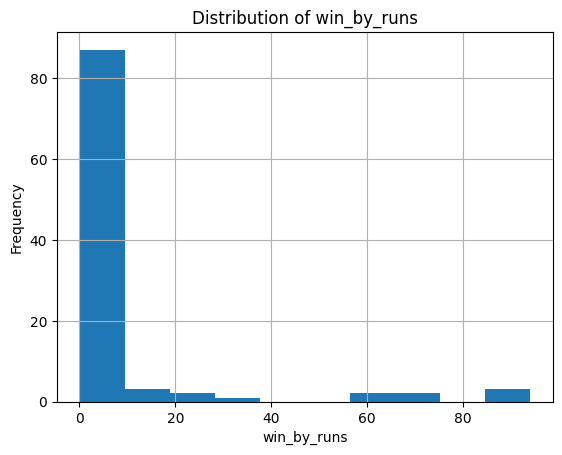

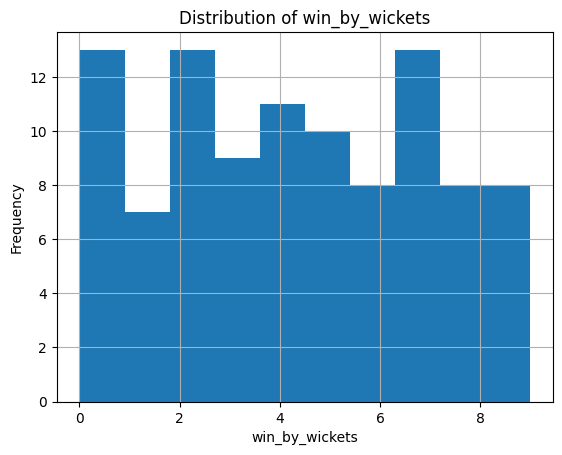

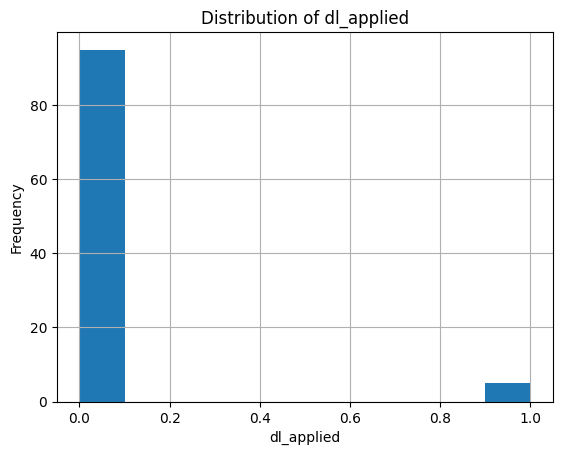

In [39]:
# Frequency Check

import matplotlib.pyplot as plt

for col in num_cols_matches:
    plt.figure()
    matches[col].hist()
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

### 🏷️ Univariate Analysis - Categorical Features

Categorical features are analyzed using value counts and bar charts.

This helps identify:
- Most frequent categories  
- Dominant teams or outcomes  

In [40]:
cat_cols_matches = ['season', 'team1', 'team2', 'toss_winner', 'toss_decision', 'winner']

for col in cat_cols_matches:
    print(f"\nValue counts for {col}:")
    print(matches[col].value_counts().head(10))


Value counts for season:
season
2018    26
2016    21
2019    19
2015    18
2017    16
Name: count, dtype: int64

Value counts for team1:
team1
Mumbai Indians                 17
Kings XI Punjab                17
Royal Challengers Bangalore    15
Sunrisers Hyderabad            14
Delhi Capitals                 11
Kolkata Knight Riders          10
Rajasthan Royals               10
Chennai Super Kings             6
Name: count, dtype: int64

Value counts for team2:
team2
Kings XI Punjab                21
Mumbai Indians                 16
Delhi Capitals                 16
Royal Challengers Bangalore    15
Sunrisers Hyderabad            13
Kolkata Knight Riders           7
Rajasthan Royals                6
Chennai Super Kings             6
Name: count, dtype: int64

Value counts for toss_winner:
toss_winner
Kings XI Punjab                17
Mumbai Indians                 15
Kolkata Knight Riders          13
Chennai Super Kings            13
Sunrisers Hyderabad            11
Rajasthan Royal

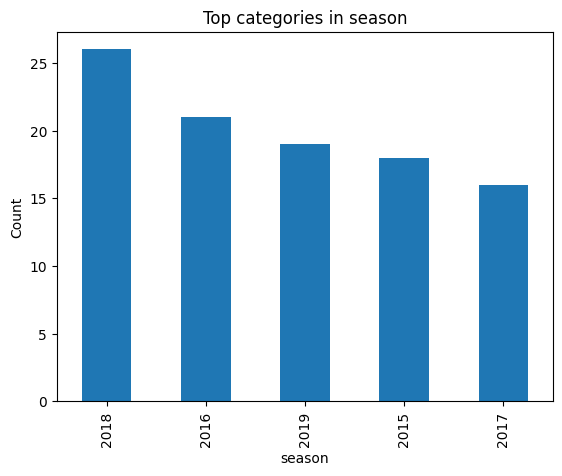

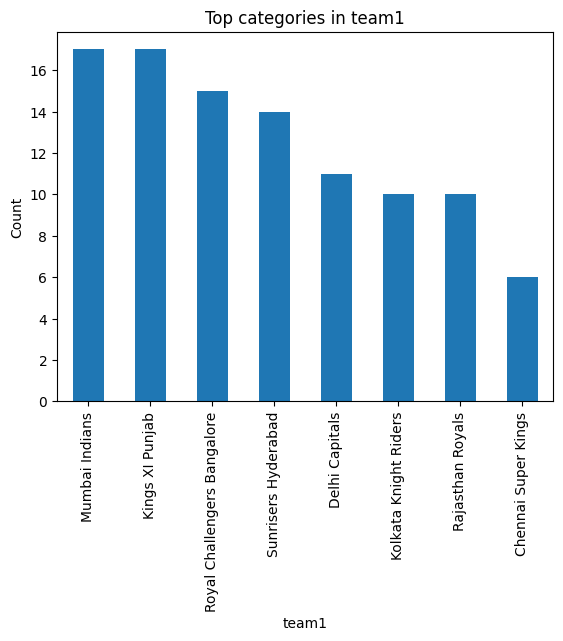

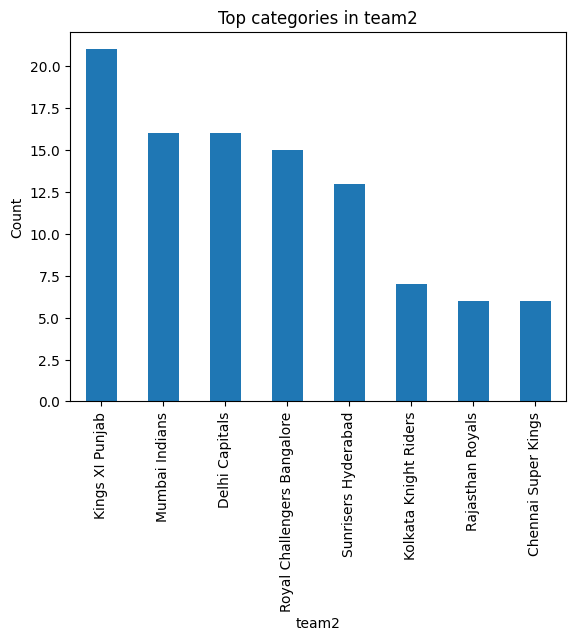

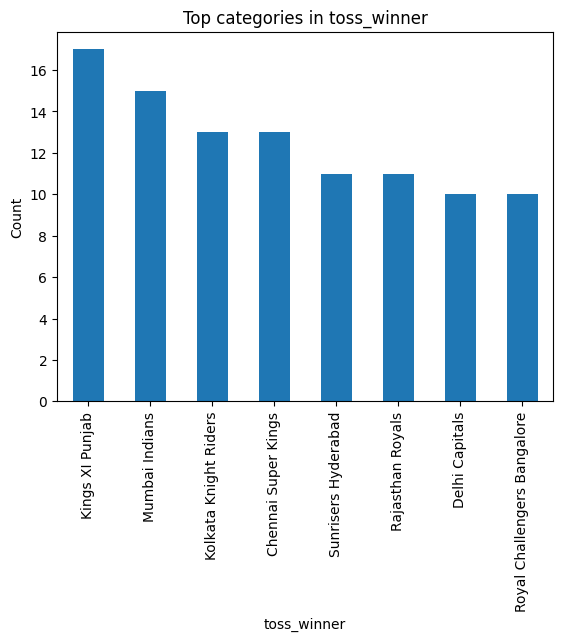

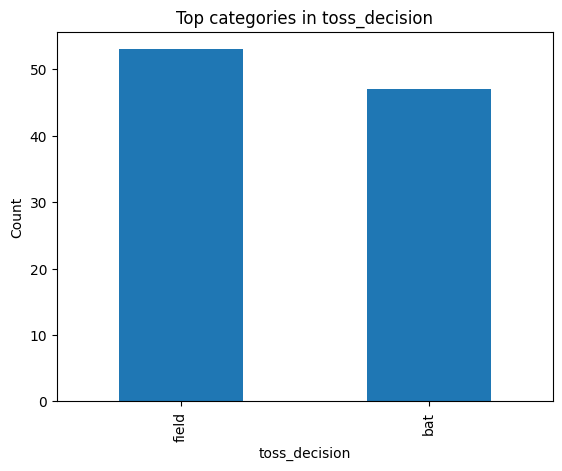

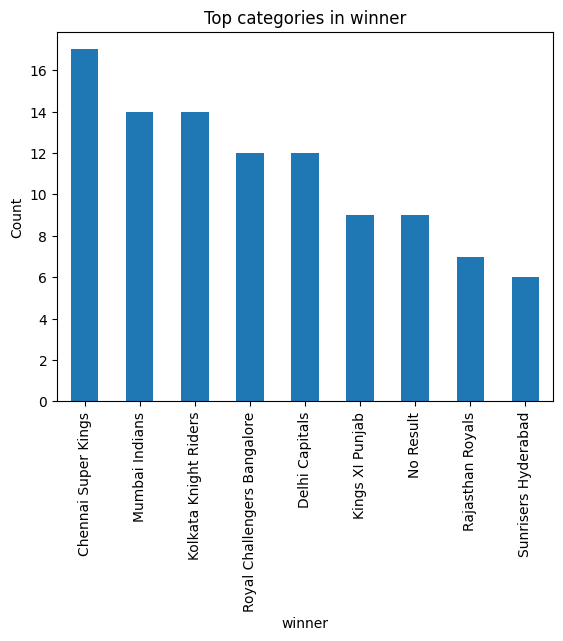

In [41]:
for col in cat_cols_matches:
    plt.figure()
    matches[col].value_counts().head(10).plot(kind='bar')
    plt.title(f"Top categories in {col}")
    plt.ylabel("Count")
    plt.show()

### 📝 Univariate Analysis - String Features

String features mainly include names and textual information.

We analyze:
- Most frequent values  
- Unique counts  

These features are useful for identifying key players and entities.

In [42]:
str_cols = ['city', 'umpire1', 'umpire2']

for col in str_cols:
    print(f"\nTop values in {col}:")
    print(matches[col].value_counts().head(10))


Top values in city:
city
Jaipur        18
Hyderabad     15
Mumbai        13
Delhi         13
Bangalore     13
Chennai       12
Chandigarh     9
Kolkata        7
Name: count, dtype: int64

Top values in umpire1:
umpire1
Asad Rauf          39
HDPK Dharmasena    33
AK Chaudhary       28
Name: count, dtype: int64

Top values in umpire2:
umpire2
SJA Taufel       36
S Ravi           34
C Shamshuddin    30
Name: count, dtype: int64


### 📅 Univariate Analysis - Datetime Features

Datetime features help in understanding trends over time.

We will extract:
- Year  
- Month  

to analyze temporal patterns.

In [43]:
matches['year'] = matches['date'].dt.year
matches['month'] = matches['date'].dt.month

print(matches['year'].value_counts().sort_index())

year
2015    100
Name: count, dtype: int64


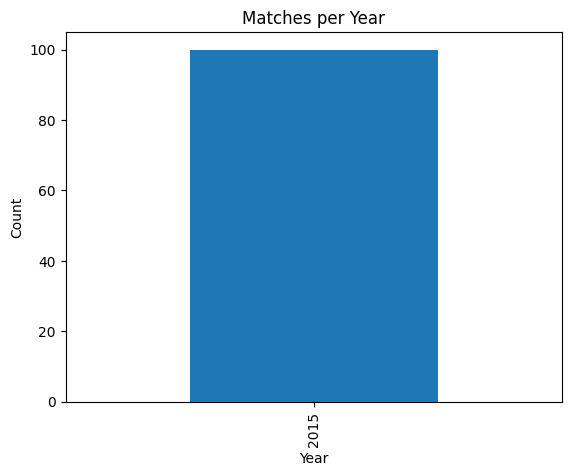

In [44]:
matches['year'].value_counts().sort_index().plot(kind='bar')
plt.title("Matches per Year")
plt.xlabel("Year")
plt.ylabel("Count")
plt.show()

## Bivariate Analysis :

In this step, we perform bivariate analysis by systematically combining different types of features.

We follow this approach:

1. Numerical vs Numerical  
2. Numerical vs Categorical  
3. Numerical vs String  
4. Numerical vs Datetime  

For each combination:
- We iterate over all possible column pairs  
- Generate appropriate visualizations  
- Analyze relationships between variables  

This structured approach ensures comprehensive coverage of feature interactions.

# Writing the Bivariate Analysis insights here:
### 📌 Insights - Numerical vs Numerical

- **win_by_runs vs win_by_wickets:** Matches are won either by runs or wickets (not both), showing a mutually exclusive relationship.  

- **win_by_runs vs dl_applied:** There is no clear relationship, as DL method is applied independently of run margins.  

- **win_by_wickets vs dl_applied:** DL-applied matches occur across different wicket margins, indicating no strong dependency.  

### 📌 Insights - Numerical vs Categorical

- Teams differ in their average winning margins, indicating varying dominance levels.  

- Certain teams win by larger run margins, suggesting strong batting performance.  

- Teams choosing to bat first tend to win by higher run margins.  

- Teams choosing to field first tend to win with more wickets in hand, indicating chasing advantage.  

### 📌 Insights - Numerical vs String

- Certain cities show higher average win margins, indicating pitch or venue influence on match outcomes.  

- Some venues favor chasing teams, as seen in higher average wins by wickets.  

- Umpire-based variations exist but do not show strong or meaningful impact on match outcomes.  

### 📌 Insights - Numerical vs Datetime

- **win_by_runs over year:** Average win margins by runs fluctuate over the years but remain within a similar range, indicating consistent competition levels.  

- **win_by_wickets over year:** Average wins by wickets show minor variation, suggesting stable chasing performance across seasons.  

- **dl_applied over year:** DL method usage is inconsistent and relatively low, indicating occasional match interruptions without a clear trend.  

### 📌 Insights - Categorical vs Categorical

- Teams winning the toss have a higher probability of winning the match.  

- Toss decisions influence match outcomes, with teams preferring to field first.  

- The role of toss is important but not decisive, as match performance still plays a key role.  

### 📌 Insights - Categorical vs String

- Certain teams dominate specific cities (e.g., RCB in Bangalore), indicating strong home-ground advantage.  

- Teams prefer to field more often across most cities, suggesting pitch conditions generally favor chasing.  

### 📌 Insights - Year vs Winner

- Different teams dominate in different seasons, indicating that team performance varies over time rather than being consistently dominated by a single team.  

### 📌 Insights - String vs Datetime

- The distribution of matches across cities changes over time, reflecting expansion and variation in IPL venues.  


### 🔢 Numerical vs Numerical

This helps in understanding relationships between numeric variables using correlation and scatter plots.

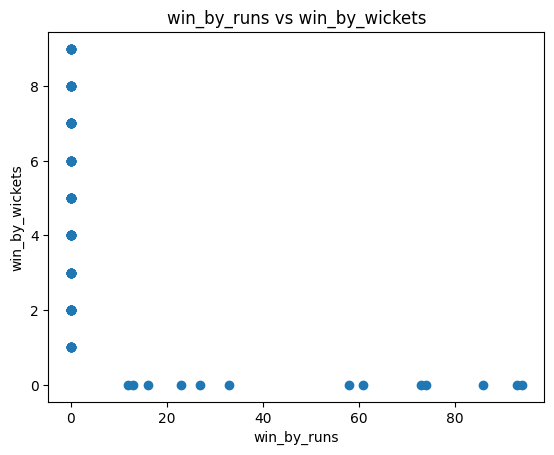

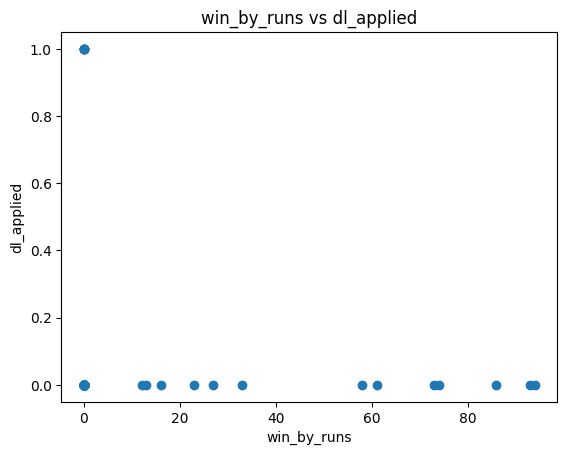

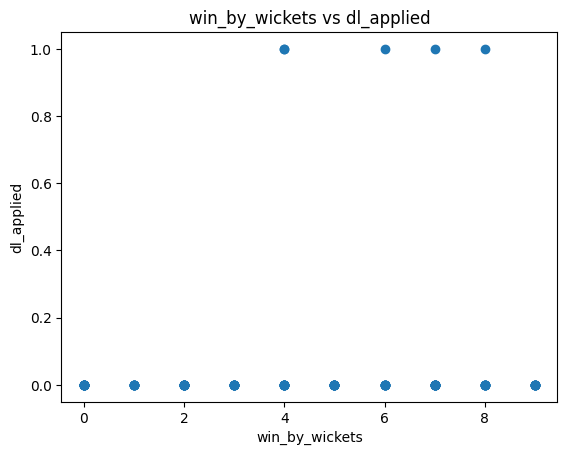

In [45]:
num_cols = ['win_by_runs', 'win_by_wickets', 'dl_applied']

import itertools

for col1, col2 in itertools.combinations(num_cols, 2):
    plt.figure()
    plt.scatter(matches[col1], matches[col2])
    plt.xlabel(col1)
    plt.ylabel(col2)
    plt.title(f"{col1} vs {col2}")
    plt.show()

### 🏷️ Numerical vs Categorical

This helps compare numerical values across different categories using boxplots or bar plots.

In [46]:
matches.groupby('winner')["win_by_runs"].mean()

,win_by_runs
winner,
Chennai Super Kings,2.529412
Delhi Capitals,2.750000
Kings XI Punjab,31.888889
Kolkata Knight Riders,0.857143
Mumbai Indians,0.000000
No Result,30.555556
Rajasthan Royals,0.000000
Royal Challengers Bangalore,1.083333
Sunrisers Hyderabad,0.000000


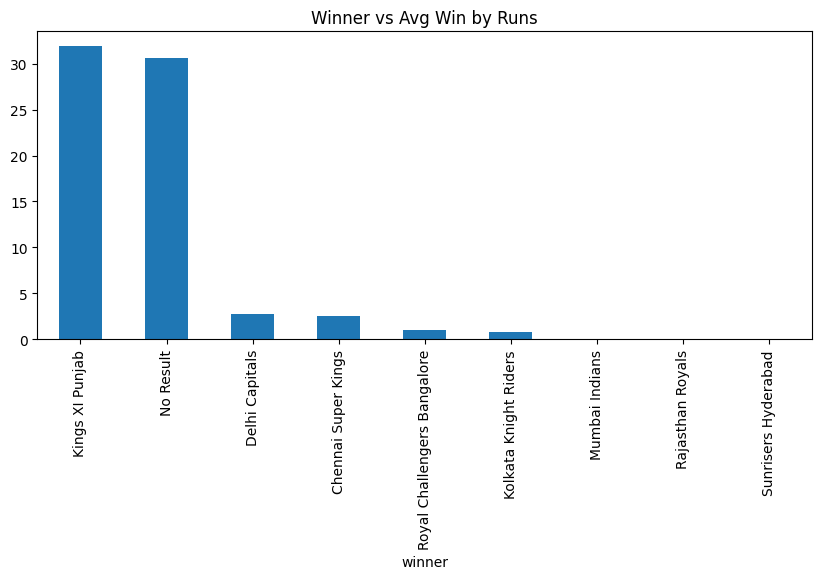

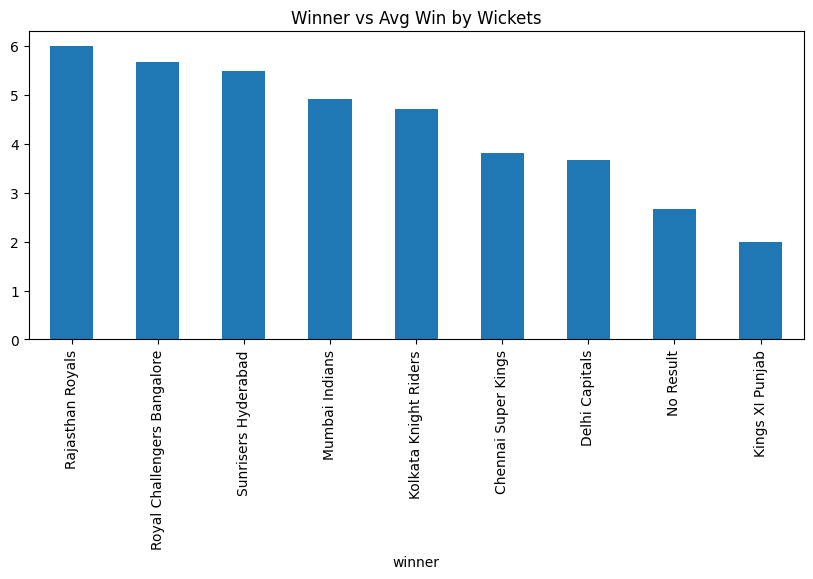

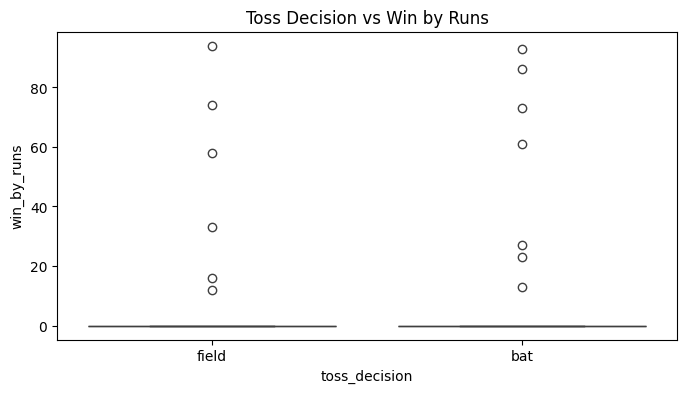

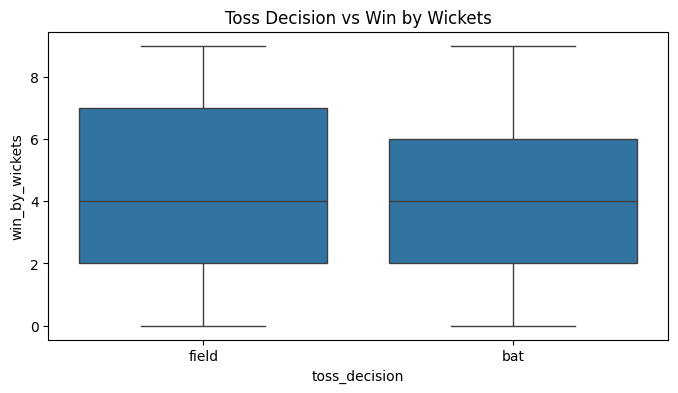

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Winner vs win_by_runs
plt.figure(figsize=(10,4))
matches.groupby('winner')['win_by_runs'].mean().sort_values(ascending=False).head(10).plot(kind='bar')
plt.title("Winner vs Avg Win by Runs")
plt.show()


# 2. Winner vs win_by_wickets
plt.figure(figsize=(10,4))
matches.groupby('winner')['win_by_wickets'].mean().sort_values(ascending=False).head(10).plot(kind='bar')
plt.title("Winner vs Avg Win by Wickets")
plt.show()


# 3. Toss decision vs win_by_runs
plt.figure(figsize=(8,4))
sns.boxplot(x='toss_decision', y='win_by_runs', data=matches)
plt.title("Toss Decision vs Win by Runs")
plt.show()


# 4. Toss decision vs win_by_wickets
plt.figure(figsize=(8,4))
sns.boxplot(x='toss_decision', y='win_by_wickets', data=matches)
plt.title("Toss Decision vs Win by Wickets")
plt.show()

# Numerical VS String :

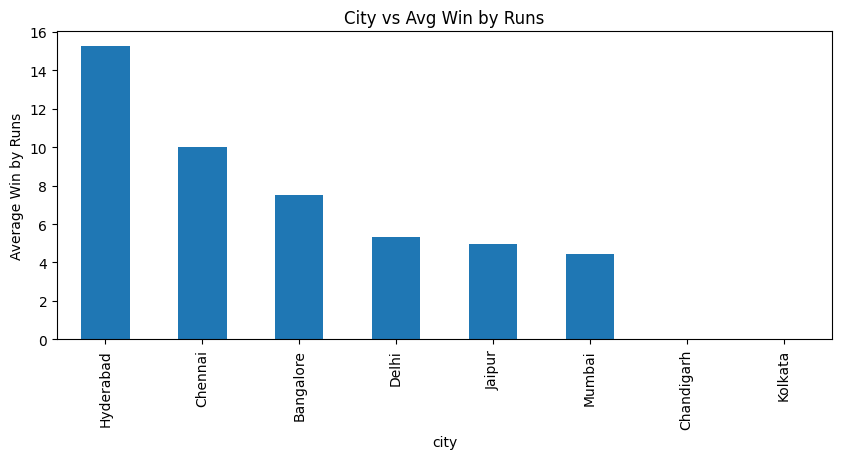

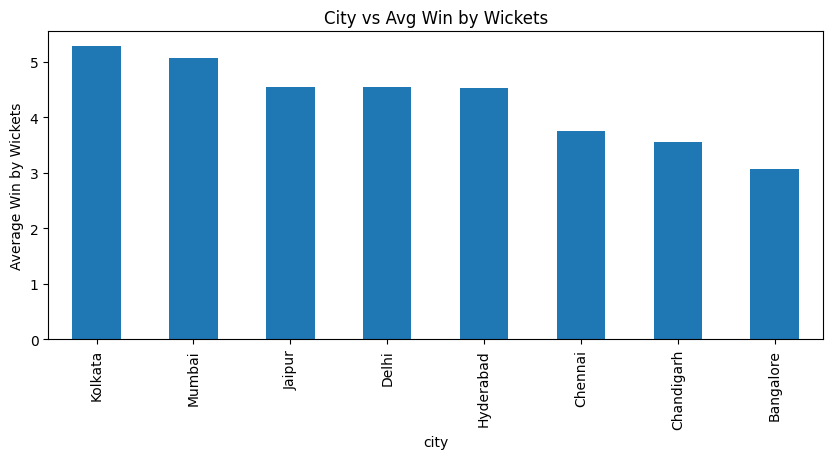

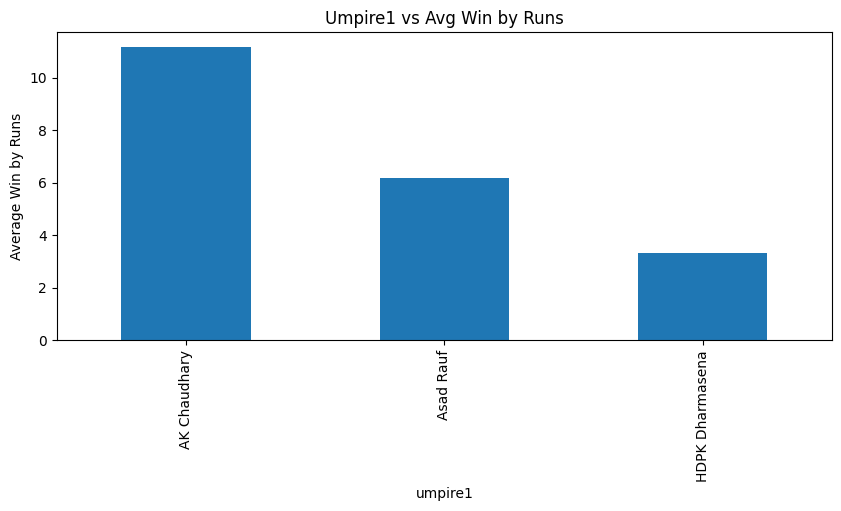

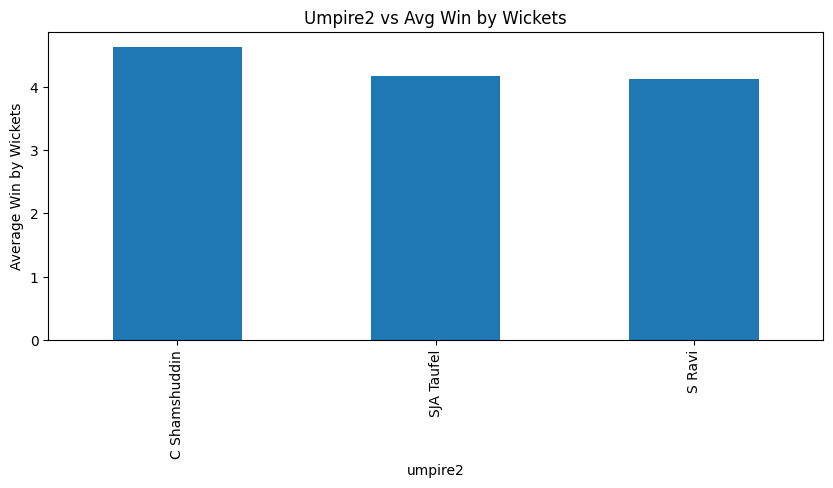

In [48]:
import matplotlib.pyplot as plt

# 1. City vs win_by_runs
plt.figure(figsize=(10,4))
matches.groupby('city')['win_by_runs'].mean().sort_values(ascending=False).head(10).plot(kind='bar')
plt.title("City vs Avg Win by Runs")
plt.ylabel("Average Win by Runs")
plt.show()


# 2. City vs win_by_wickets
plt.figure(figsize=(10,4))
matches.groupby('city')['win_by_wickets'].mean().sort_values(ascending=False).head(10).plot(kind='bar')
plt.title("City vs Avg Win by Wickets")
plt.ylabel("Average Win by Wickets")
plt.show()


# 3. Umpire1 vs win_by_runs (optional but okay)
plt.figure(figsize=(10,4))
matches.groupby('umpire1')['win_by_runs'].mean().sort_values(ascending=False).head(10).plot(kind='bar')
plt.title("Umpire1 vs Avg Win by Runs")
plt.ylabel("Average Win by Runs")
plt.show()


# 4. Umpire2 vs win_by_wickets (optional)
plt.figure(figsize=(10,4))
matches.groupby('umpire2')['win_by_wickets'].mean().sort_values(ascending=False).head(10).plot(kind='bar')
plt.title("Umpire2 vs Avg Win by Wickets")
plt.ylabel("Average Win by Wickets")
plt.show()

# Numerical Vs DateTime

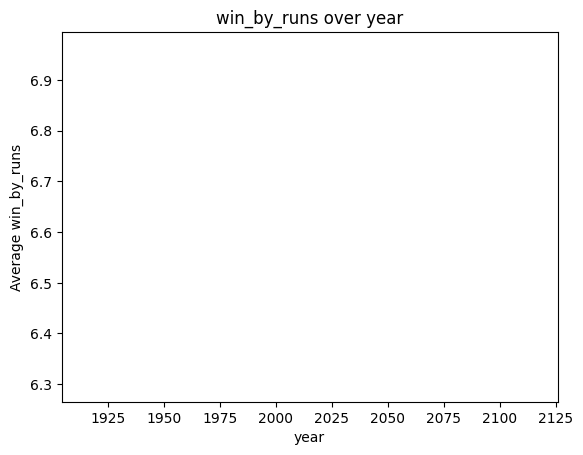

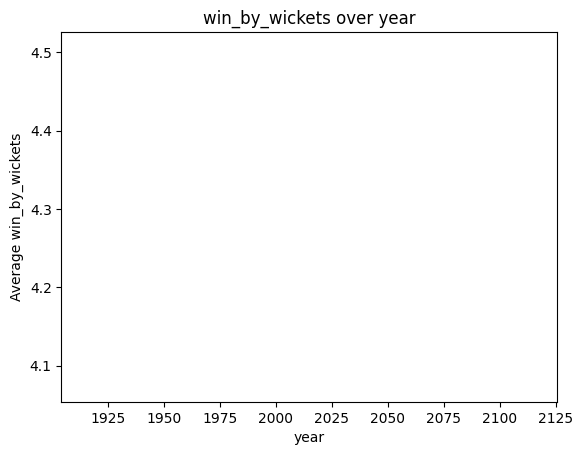

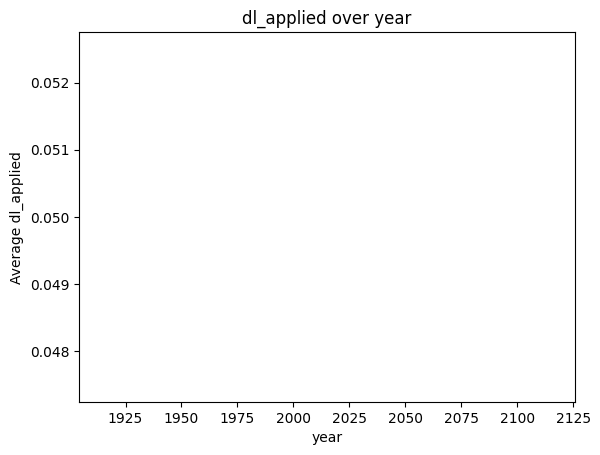

In [49]:
date_cols = ['year']  # derived earlier

for num in num_cols:
    for date in date_cols:
        plt.figure()
        matches.groupby(date)[num].mean().plot()
        plt.title(f"{num} over {date}")
        plt.ylabel(f"Average {num}")
        plt.show()

### 🏷️ Categorical vs Categorical

This analysis helps in understanding relationships between categorical variables using count plots and cross-tabulation.

It is one of the most important analyses for extracting meaningful insights.

In [50]:
important_pairs = [
    ('toss_winner', 'winner'),
    ('toss_decision', 'winner'),
    ('team1', 'winner'),
    ('team2', 'winner')
]

In [51]:
for col1, col2 in important_pairs:
    print(f"\n{col1} vs {col2}")

    ct = pd.crosstab(matches[col1], matches[col2], normalize='index') * 100
    display(ct.round(2).head(10))


toss_winner vs winner


winner,Chennai Super Kings,Delhi Capitals,Kings XI Punjab,Kolkata Knight Riders,Mumbai Indians,No Result,Rajasthan Royals,Royal Challengers Bangalore,Sunrisers Hyderabad
toss_winner,,,,,,,,,
Chennai Super Kings,38.46,7.69,0.00,23.08,23.08,0.00,0.00,7.69,0.00
Delhi Capitals,10.00,20.00,20.00,10.00,20.00,0.00,10.00,10.00,0.00
Kings XI Punjab,11.76,17.65,17.65,5.88,17.65,17.65,0.00,0.00,11.76
Kolkata Knight Riders,30.77,0.00,0.00,7.69,15.38,7.69,23.08,7.69,7.69
Mumbai Indians,6.67,20.00,20.00,13.33,6.67,13.33,6.67,6.67,6.67
Rajasthan Royals,18.18,18.18,0.00,18.18,0.00,0.00,9.09,36.36,0.00
Royal Challengers Bangalore,10.00,0.00,0.00,10.00,10.00,20.00,0.00,30.00,20.00
Sunrisers Hyderabad,9.09,9.09,9.09,27.27,18.18,9.09,9.09,9.09,0.00



toss_decision vs winner


winner,Chennai Super Kings,Delhi Capitals,Kings XI Punjab,Kolkata Knight Riders,Mumbai Indians,No Result,Rajasthan Royals,Royal Challengers Bangalore,Sunrisers Hyderabad
toss_decision,,,,,,,,,
bat,17.02,12.77,8.51,4.26,8.51,12.77,10.64,17.02,8.51
field,16.98,11.32,9.43,22.64,18.87,5.66,3.77,7.55,3.77



team1 vs winner


winner,Chennai Super Kings,Delhi Capitals,Kings XI Punjab,Kolkata Knight Riders,Mumbai Indians,No Result,Rajasthan Royals,Royal Challengers Bangalore,Sunrisers Hyderabad
team1,,,,,,,,,
Chennai Super Kings,16.67,33.33,0.00,16.67,16.67,16.67,0.00,0.00,0.00
Delhi Capitals,18.18,0.00,0.00,27.27,27.27,0.00,0.00,9.09,18.18
Kings XI Punjab,17.65,5.88,23.53,5.88,11.76,17.65,11.76,0.00,5.88
Kolkata Knight Riders,30.00,30.00,0.00,10.00,0.00,10.00,10.00,10.00,0.00
Mumbai Indians,5.88,17.65,11.76,17.65,23.53,5.88,5.88,11.76,0.00
Rajasthan Royals,20.00,20.00,0.00,0.00,20.00,20.00,20.00,0.00,0.00
Royal Challengers Bangalore,26.67,0.00,13.33,13.33,13.33,0.00,0.00,33.33,0.00
Sunrisers Hyderabad,7.14,7.14,7.14,21.43,0.00,7.14,7.14,21.43,21.43



team2 vs winner


winner,Chennai Super Kings,Delhi Capitals,Kings XI Punjab,Kolkata Knight Riders,Mumbai Indians,No Result,Rajasthan Royals,Royal Challengers Bangalore,Sunrisers Hyderabad
team2,,,,,,,,,
Chennai Super Kings,0.00,33.33,16.67,16.67,0.00,16.67,0.00,0.00,16.67
Delhi Capitals,12.50,12.50,6.25,12.50,12.50,12.50,12.50,6.25,12.50
Kings XI Punjab,19.05,9.52,19.05,0.00,9.52,9.52,9.52,23.81,0.00
Kolkata Knight Riders,28.57,0.00,28.57,0.00,14.29,14.29,0.00,14.29,0.00
Mumbai Indians,18.75,18.75,0.00,18.75,12.50,0.00,6.25,18.75,6.25
Rajasthan Royals,16.67,0.00,0.00,0.00,33.33,0.00,16.67,33.33,0.00
Royal Challengers Bangalore,26.67,13.33,6.67,20.00,20.00,13.33,0.00,0.00,0.00
Sunrisers Hyderabad,7.69,7.69,0.00,38.46,15.38,7.69,7.69,0.00,15.38


In [52]:
# Toss impact
toss_win = matches[matches['toss_winner'] == matches['winner']]
print("Toss win match win %:", len(toss_win) / len(matches) * 100)

Toss win match win %: 16.0


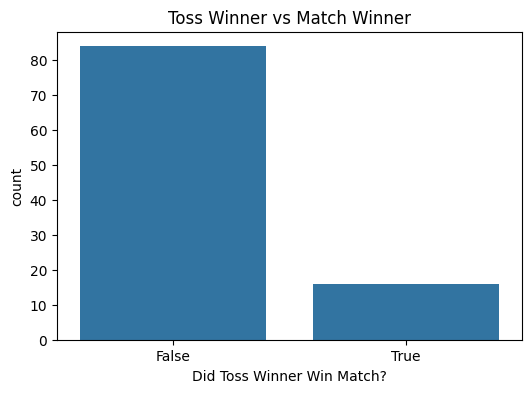

In [53]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
sns.countplot(x=(matches['toss_winner'] == matches['winner']))
plt.title("Toss Winner vs Match Winner")
plt.xlabel("Did Toss Winner Win Match?")
plt.show()

### 📝 Categorical vs String

This analysis explores relationships between categorical features and textual features such as city or umpires.

In [54]:
# 1. City vs Winner
pd.crosstab(matches['city'], matches['winner']).head()

winner,Chennai Super Kings,Delhi Capitals,Kings XI Punjab,Kolkata Knight Riders,Mumbai Indians,No Result,Rajasthan Royals,Royal Challengers Bangalore,Sunrisers Hyderabad
city,,,,,,,,,
Bangalore,3,1,1,2,3,2,0,1,0
Chandigarh,1,1,0,2,3,0,0,1,1
Chennai,1,1,1,1,2,1,1,3,1
Delhi,1,3,1,2,0,3,0,2,1
Hyderabad,1,1,4,0,3,1,1,2,2


In [55]:
# 2. City vs Toss Decision
pd.crosstab(matches['city'], matches['toss_decision']).head()

toss_decision,bat,field
city,,
Bangalore,4,9
Chandigarh,4,5
Chennai,7,5
Delhi,9,4
Hyderabad,7,8


### 📅 Categorical vs Datetime

This analysis helps in understanding how categorical variables change over time.

In [56]:
# Season vs Toss Decision
pd.crosstab(matches['year'], matches['toss_decision'])

toss_decision,bat,field
year,,
2015,47,53


In [57]:
pd.crosstab(matches['year'], matches['winner'])

winner,Chennai Super Kings,Delhi Capitals,Kings XI Punjab,Kolkata Knight Riders,Mumbai Indians,No Result,Rajasthan Royals,Royal Challengers Bangalore,Sunrisers Hyderabad
year,,,,,,,,,
2015,17,12,9,14,14,9,7,12,6


### 📅 String vs Datetime

This analysis helps understand how textual features such as cities evolve over time.

In [58]:
# Matches per city over years
pd.crosstab(matches['year'], matches['city']).head()

city,Bangalore,Chandigarh,Chennai,Delhi,Hyderabad,Jaipur,Kolkata,Mumbai
year,,,,,,,,
2015,13,9,12,13,15,18,7,13


## Multivariate Analysis

Multivariate analysis involves analyzing more than two variables simultaneously to uncover deeper patterns and relationships.

This helps in understanding how multiple factors together influence match outcomes.

# Writing Multivariate Insights here:
### 📌 Insights - Multivariate Analysis

- **Toss + Toss Decision → Winner:** Teams winning the toss and choosing to field tend to have a higher chance of winning the match.  

- **City + Team → Winner:** Teams perform better in certain cities, confirming strong home-ground or venue advantage.  

- **Season + Team → Winner:** Different teams dominate across different seasons, showing dynamic competition over time.  

- **City + Toss Decision → Winner:** Toss decisions vary by venue, and certain strategies (like fielding first) work better in specific cities.  

- **Toss Winner vs Match Winner (Heatmap):** Teams winning the toss often win the match, but the relationship is not perfectly deterministic.  

In [59]:
matches['toss_winner'] == matches['winner']

,0
0,False
1,False
2,True
3,True
4,False
...,...
95,False
96,False
97,False
98,False


In [60]:
# Toss winner = match winner?
matches['toss_win_match_win'] = matches['toss_winner'] == matches['winner']

pd.crosstab(
    [matches['toss_winner'], matches['toss_decision']],
    matches['toss_win_match_win']
)

toss_win_match_win                         False  True 
toss_winner                 toss_decision              
Chennai Super Kings         bat                1      4
                            field              7      1
Delhi Capitals              bat                4      1
                            field              4      1
Kings XI Punjab             bat                8      1
                            field              6      2
Kolkata Knight Riders       bat                5      0
                            field              7      1
Mumbai Indians              bat                8      1
                            field              6      0
Rajasthan Royals            bat                4      0
                            field              6      1
Royal Challengers Bangalore bat                2      3
                            field              5      0
Sunrisers Hyderabad         bat                5      0
                            field              6      0

In [61]:
pd.crosstab(
    [matches['city'], matches['team1']],
    matches['winner']
).head()

winner                           Chennai Super Kings  Delhi Capitals  \
city      team1                                                        
Bangalore Chennai Super Kings                      1               0   
          Delhi Capitals                           0               0   
          Kings XI Punjab                          0               0   
          Kolkata Knight Riders                    0               0   
          Mumbai Indians                           0               0   

winner                           Kings XI Punjab  Kolkata Knight Riders  \
city      team1                                                           
Bangalore Chennai Super Kings                  0                      0   
          Delhi Capitals                       0                      0   
          Kings XI Punjab                      1                      1   
          Kolkata Knight Riders                0                      1   
          Mumbai Indians                       0                      0   

winner                           Mumbai Indians  No Result  Rajasthan Royals  \
city      team1                                                                
Bangalore Chennai Super Kings                 0          0                 0   
          Delhi Capitals                      1          0                 0   
          Kings XI Punjab                     0          1                 0   
          Kolkata Knight Riders               0          0                 0   
          Mumbai Indians                      1          0                 0   

winner                           Royal Challengers Bangalore  \
city      team1                                                
Bangalore Chennai Super Kings                              0   
          Delhi Capitals                                   0   
          Kings XI Punjab                                  0   
          Kolkata Knight Riders                            0   
          Mumbai Indians                                   0   

winner                           Sunrisers Hyderabad  
city      team1                                       
Bangalore Chennai Super Kings                      0  
          Delhi Capitals                           0  
          Kings XI Punjab                          0  
          Kolkata Knight Riders                    0  
          Mumbai Indians                           0

In [62]:
pd.crosstab(
    matches['season'],
    matches['winner']
)

winner,Chennai Super Kings,Delhi Capitals,Kings XI Punjab,Kolkata Knight Riders,Mumbai Indians,No Result,Rajasthan Royals,Royal Challengers Bangalore,Sunrisers Hyderabad
season,,,,,,,,,
2015,3,3,1,2,2,2,3,2,0
2016,1,3,2,7,1,2,0,2,3
2017,6,1,0,2,4,1,1,1,0
2018,1,3,3,2,6,3,3,3,2
2019,6,2,3,1,1,1,0,4,1


In [63]:
pd.crosstab(
    [matches['city'], matches['toss_decision']],
    matches['winner']
)

winner                    Chennai Super Kings  Delhi Capitals  \
city       toss_decision                                        
Bangalore  bat                              1               0   
           field                            2               1   
Chandigarh bat                              0               1   
           field                            1               0   
Chennai    bat                              1               0   
           field                            0               1   
Delhi      bat                              1               2   
           field                            0               1   
Hyderabad  bat                              0               0   
           field                            1               1   
Jaipur     bat                              1               2   
           field                            4               1   
Kolkata    bat                              1               0   
           field                            1               0   
Mumbai     bat                              3               1   
           field                            0               1   

winner                    Kings XI Punjab  Kolkata Knight Riders  \
city       toss_decision                                           
Bangalore  bat                          0                      0   
           field                        1                      2   
Chandigarh bat                          0                      0   
           field                        0                      2   
Chennai    bat                          0                      1   
           field                        1                      0   
Delhi      bat                          1                      1   
           field                        0                      1   
Hyderabad  bat                          2                      0   
           field                        2                      0   
Jaipur     bat                          1                      0   
           field                        0                      2   
Kolkata    bat                          0                      0   
           field                        0                      3   
Mumbai     bat                          0                      0   
           field                        1                      2   

winner                    Mumbai Indians  No Result  Rajasthan Royals  \
city       toss_decision                                                
Bangalore  bat                         1          2                 0   
           field                       2          0                 0   
Chandigarh bat                         1          0                 0   
           field                       2          0                 0   
Chennai    bat                         0          1                 1   
           field                       2          0                 0   
Delhi      bat                         0          2                 0   
           field                       0          1                 0   
Hyderabad  bat                         1          0                 1   
           field                       2          1                 0   
Jaipur     bat                         1          1                 1   
           field                       1          0                 1   
Kolkata    bat                         0          0                 0   
           field                       0          0                 0   
Mumbai     bat                         0          0                 2   
           field                       1          1                 1   

winner                    Royal Challengers Bangalore  Sunrisers Hyderabad  
city       toss_decision                                                    
Bangalore  bat                                      0                    0  
           field                                    1     

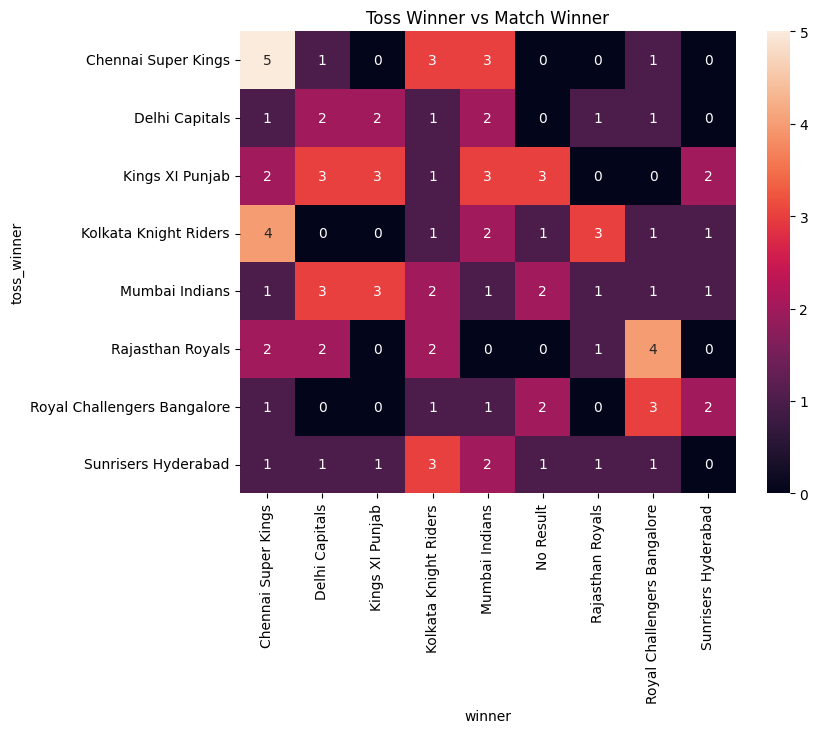

In [64]:
import seaborn as sns
import matplotlib.pyplot as plt

ct = pd.crosstab(matches['toss_winner'], matches['winner'])

plt.figure(figsize=(8,6))
sns.heatmap(ct, annot=True, fmt='d')
plt.title("Toss Winner vs Match Winner")
plt.show()